# Análise Exploratória e Aprendizado Descritivo: Perfilamento de Cursos e Instrutores da Udemy

## Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from mlxtend.frequent_patterns import fpgrowth, association_rules

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## Funções

In [2]:
def parse_duration(duration_str):
    if pd.isna(duration_str): return np.nan
    duration_str = str(duration_str).lower()
    try:
        val = float(re.findall(r'[\d\.]+', duration_str)[0])
        return val if 'hour' in duration_str else val / 60
    except:
        return np.nan
    
def extrair_senioridade_unica(title):
    """Extrai uma variável categórica de senioridade baseada no cargo do mercado."""
    if pd.isna(title): return '5. Não Informado/Outros'
    title = str(title).lower()
    if any(w in title for w in ['founder', 'ceo', 'cto', 'president', 'owner', 'c-level']):
        return '1. Executivo/C-Level'
    elif any(w in title for w in ['head', 'director', 'vp', 'principal']):
        return '2. Diretoria/Head'
    elif any(w in title for w in ['manager', 'lead', 'senior', 'sr', 'expert', 'architect']):
        return '3. Sênior/Liderança'
    elif any(w in title for w in ['instructor', 'professor', 'teacher', 'phd', 'academic']):
        return '4. Acadêmico/Educador'
    return '5. Pleno/Júnior/Outros'

def padronizar_papeis_lista(title):
    """Gera uma lista de papéis/áreas de atuação formatada para o algoritmo Apriori."""
    if pd.isna(title): return ['Outros']
    title = str(title).lower()
    roles = set()
    if any(w in title for w in ['data scientist', 'machine learning', 'ai', 'data analyst']):
        roles.add('Data Professional')
    if any(w in title for w in ['developer', 'programmer', 'software engineer', 'web']):
        roles.add('Software Developer')
    if any(w in title for w in ['designer', 'ux', 'ui', 'art', '3d']):
        roles.add('Designer/Artist')
    if any(w in title for w in ['marketing', 'sales', 'business', 'finance']):
        roles.add('Business/Finance')
    if len(roles) == 0: roles.add('Outros')
    return list(roles)

def extrair_subgrupos_formatados(regras_df, target_consequente):
    """
    Filtra as regras globais para isolar os subgrupos de interesse e 
    aplica formatação textual adequada para apresentação e exportação.
    """
    subgrupo = regras_df[regras_df['consequents'] == frozenset({target_consequente})].copy()
    
    # Tratamento visual das strings (remoção do encapsulamento 'frozenset')
    subgrupo['antecedents'] = subgrupo['antecedents'].apply(lambda x: ' + '.join(list(x)))
    subgrupo['consequents'] = subgrupo['consequents'].apply(lambda x: list(x)[0])
    
    # Ordenação decrescente por relevância analítica (Lift > Confidence > Support)
    subgrupo = subgrupo.sort_values(by=['lift', 'confidence', 'support'], ascending=[False, False, False])
    
    # Seleção das métricas vitais para a tomada de decisão
    colunas_finais = ['antecedents', 'consequents', 'support', 'confidence', 'lift']
    
    return subgrupo[colunas_finais]

## Carregamento e Mesclagem dos Dados

In [3]:
df_courses = pd.read_csv('courses.csv')
df_instructors = pd.read_csv('instructors.csv')

df = pd.merge(
    df_courses, 
    df_instructors, 
    left_on='instructors_id', 
    right_on='id', 
    how='left', 
    suffixes=('_course', '_instructor')
)

## Engenharia de Recursos (Limpeza e Criação de Métricas)

In [4]:
# Tratamento de Dados Ausentes (Recodificação de Zeros na Nota)
df['rating'] = df['rating'].replace(0, np.nan)

# Métricas de Autoridade do Instrutor (Agregação)
# Cálculo do portfólio total e da nota média global de cada instrutor
instructor_stats = df.groupby('instructors_id').agg(
    inst_total_courses=('id_course', 'count'),
    inst_total_reviews=('num_reviews', 'sum'),
    inst_avg_rating=('rating', 'mean')
).reset_index()

# Atualização do dataframe principal, removendo colunas duplicadas caso existam
if 'inst_total_courses' in df.columns:
    df = df.drop(columns=['inst_total_courses', 'inst_total_reviews', 'inst_avg_rating'])
df = pd.merge(df, instructor_stats, on='instructors_id', how='left')

df['inst_seniority_level'] = df['job_title'].apply(extrair_senioridade_unica)
df['inst_standardized_roles'] = df['job_title'].apply(padronizar_papeis_lista)

# Análise Temporal: Ciclo de Vida e Manutenção do Portfólio (Snapshot)
df['created'] = pd.to_datetime(df['created']).dt.tz_localize(None)
df['last_update_date'] = pd.to_datetime(df['last_update_date']).dt.tz_localize(None)

data_referencia = df['last_update_date'].max()
df['idade_curso_meses'] = (data_referencia - df['created']).dt.days / 30
df['meses_sem_atualizacao'] = (data_referencia - df['last_update_date']).dt.days / 30

# Conversão inicial da string de duração para valor numérico em horas
df['duration_hours'] = df['duration'].apply(parse_duration)

# Preenchimento de nulos com a mediana para manter a integridade da base antes da discretização
df['duration_hours'] = df['duration_hours'].fillna(df['duration_hours'].median())

# -----------------------------------------------------------------------------
# Discretização de Variáveis Contínuas
# -----------------------------------------------------------------------------

# Densidade do Conteúdo (Volume de Aulas)
bins_aulas = [0, 15, 50, float('inf')]
df['cat_volume_aulas'] = pd.cut(df['num_published_lectures'], bins=bins_aulas, labels=['Poucas Aulas (<15)', 'Média (15-50)', 'Curso Denso (>50)'])

# Extensão do Curso (Duração Total)
bins_duration = [0, 2, 10, float('inf')]
df['cat_duration'] = pd.cut(df['duration_hours'], bins=bins_duration, labels=['Curto (<2h)', 'Médio (2-10h)', 'Longo (>10h)'])

# Qualidade Percebida (Nota/Rating)
bins_rating = [0, 3.5, 4.5, 5.0]
df['cat_rating'] = pd.cut(df['rating'], bins=bins_rating, labels=['Baixa (<3.5)', 'Média (3.5 - 4.5)', 'Alta (>4.5)'])

# Autoridade do Instrutor (Tamanho do Portfólio)
bins_inst = [0, 1, 5, float('inf')]
df['cat_instructor_size'] = pd.cut(df['inst_total_courses'], bins=bins_inst, labels=['Iniciante (1)', 'Intermediário (2-5)', 'Experiente (>5)'])

# Maturidade do Produto (Idade no Catálogo)
bins_idade = [0, 12, 36, float('inf')]
df['cat_maturidade_curso'] = pd.cut(df['idade_curso_meses'], bins=bins_idade, labels=['Lançamento (<1 ano)', 'Estabelecido (1-3 anos)', 'Catálogo Antigo (>3 anos)'])

# Manutenção do Produto (Frescor de Atualização)
bins_frescor = [0, 6, 18, float('inf')]
df['cat_frescor_atualizacao'] = pd.cut(df['meses_sem_atualizacao'], bins=bins_frescor, labels=['Recente (<6 meses)', 'Moderado (6-18 meses)', 'Desatualizado (>18 meses)'])

## Análise exploratória

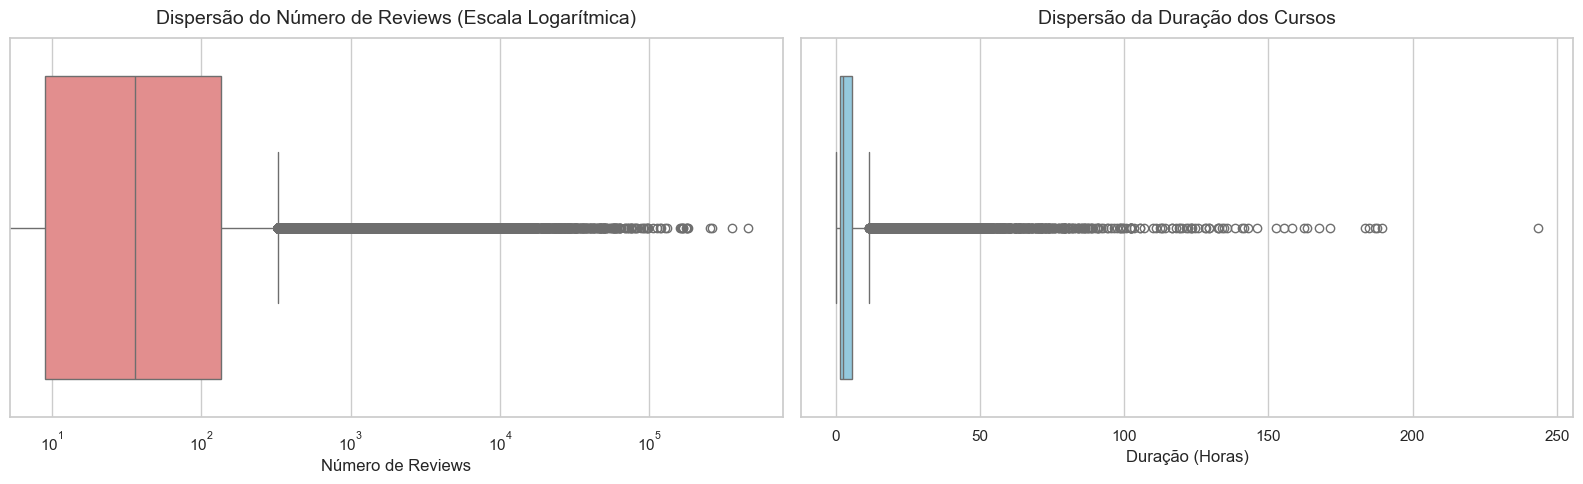

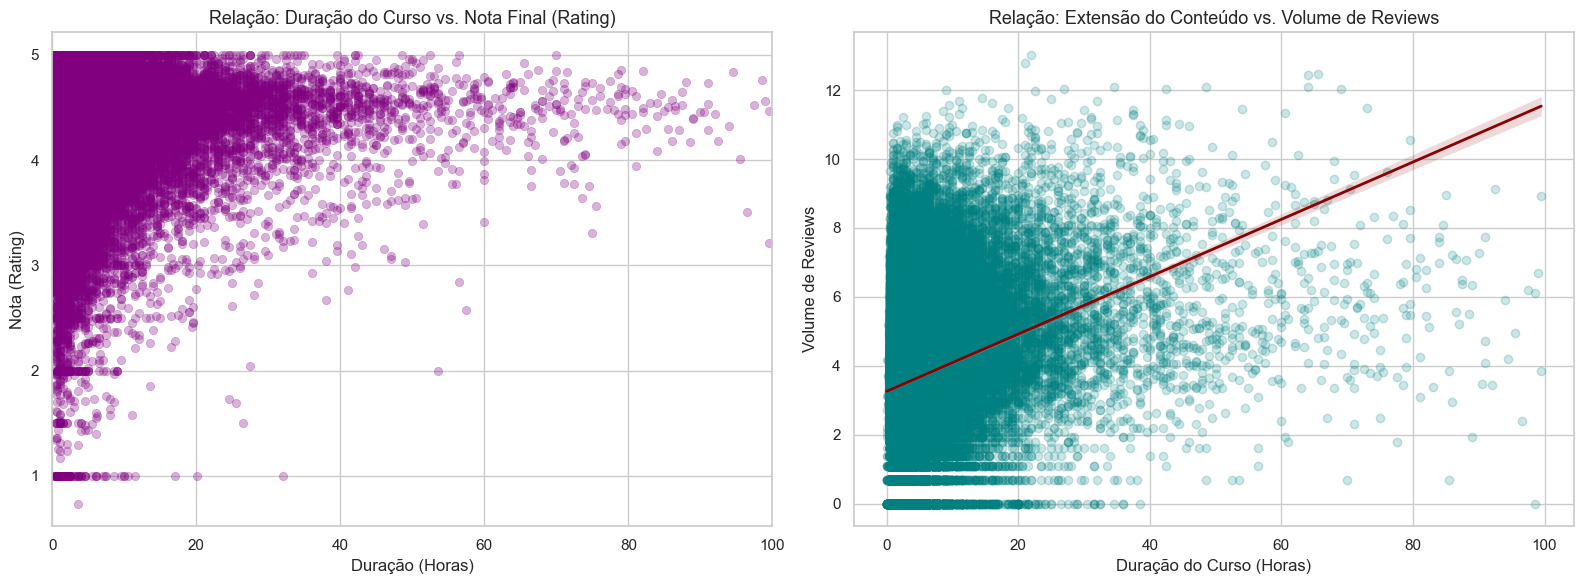

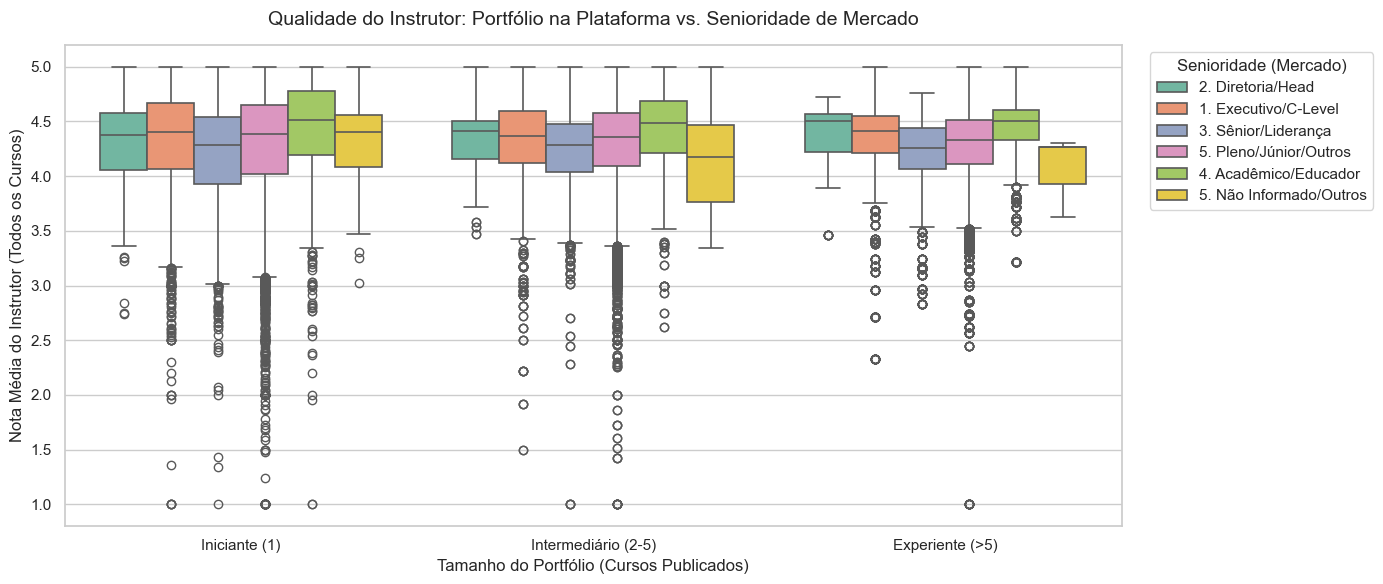

C:\Users\raini\AppData\Local\Temp\ipykernel_13924\1988921523.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='cat_duration', ax=axes[0,0], palette='viridis', edgecolor='black')
C:\Users\raini\AppData\Local\Temp\ipykernel_13924\1988921523.py:58: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='cat_rating', ax=axes[0,1], palette='magma', edgecolor='black')
C:\Users\raini\AppData\Local\Temp\ipykernel_13924\1988921523.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='cat_maturidade_curso', ax=axes[1,

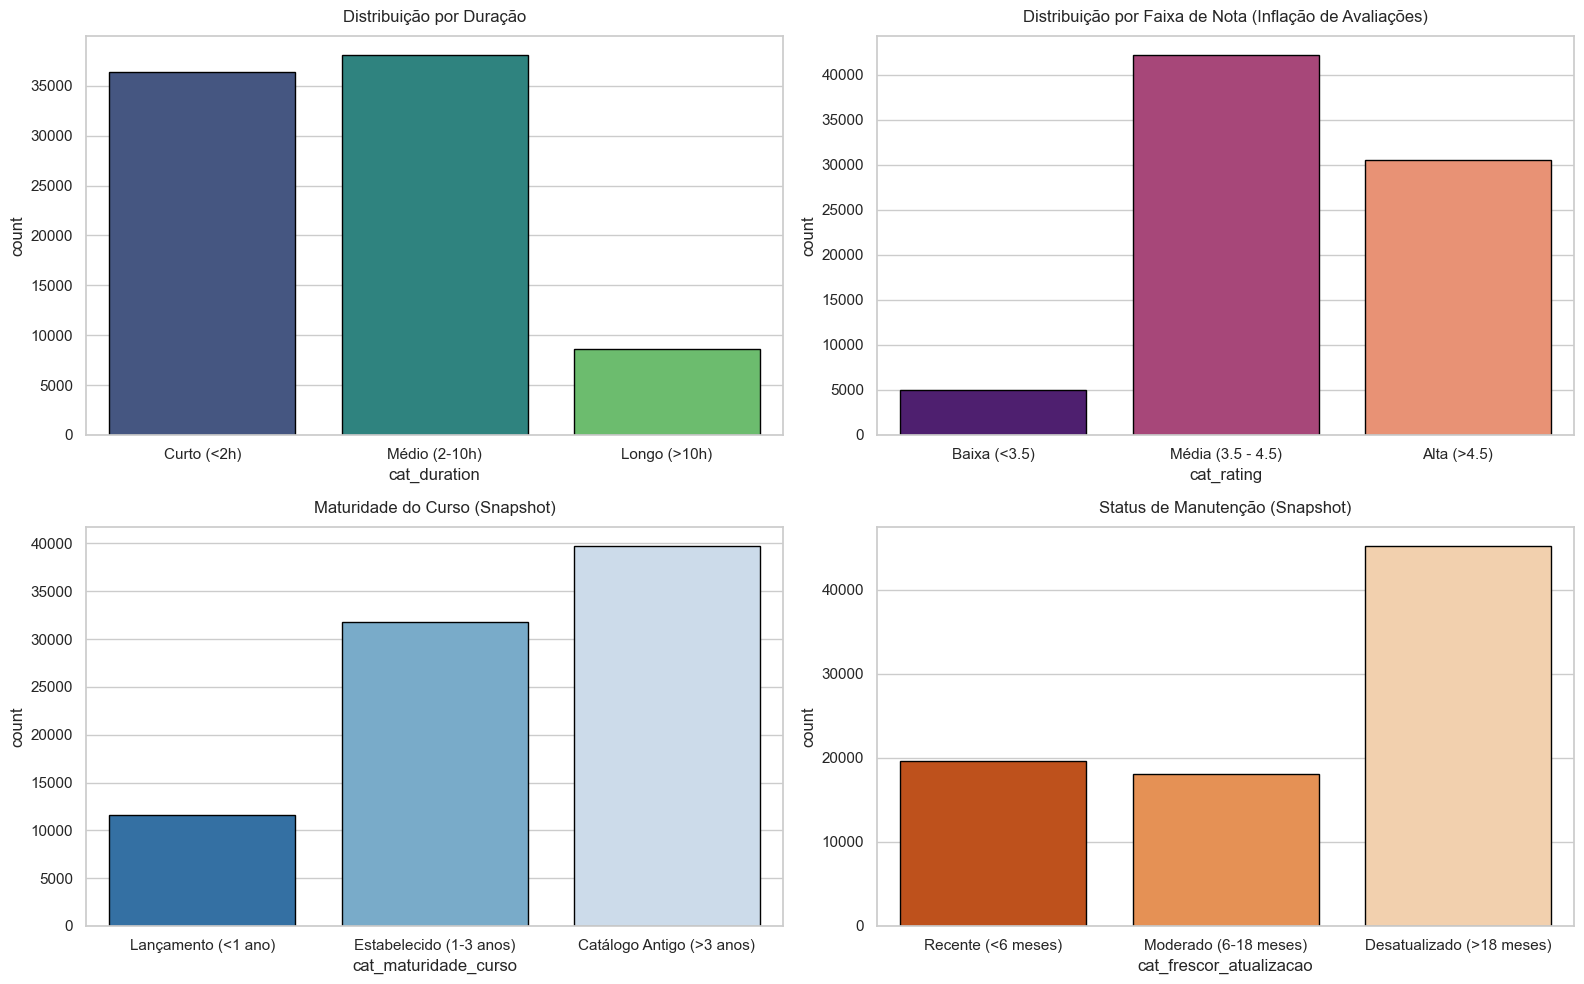

In [5]:
# Análise Univariada
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(x=df['num_reviews'], ax=axes[0], color='lightcoral')
axes[0].set_title('Dispersão do Número de Reviews (Escala Logarítmica)', fontsize=14, pad=10)
axes[0].set_xscale('log') 
axes[0].set_xlabel('Número de Reviews')

sns.boxplot(x=df['duration_hours'], ax=axes[1], color='skyblue')
axes[1].set_title('Dispersão da Duração dos Cursos', fontsize=14, pad=10)
axes[1].set_xlabel('Duração (Horas)')
plt.tight_layout()
plt.show()

# Hipóteses Bivariadas: Duração vs. Engajamento e Qualidade
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Teste 1: Duração vs Nota (A percepção de qualidade cai com cursos longos?)
sns.scatterplot(data=df, x='duration_hours', y='rating', alpha=0.3, color='purple', edgecolor=None, ax=axes[0])
axes[0].set_title('Relação: Duração do Curso vs. Nota Final (Rating)', fontsize=13)
axes[0].set_xlabel('Duração (Horas)')
axes[0].set_ylabel('Nota (Rating)')
axes[0].set_xlim(0, 100) 

# Teste 2: Duração vs Volume de Avaliações (Hipótese de abandono em cursos longos)
df_filtrado = df[df['duration_hours'] <= 100].copy()
df_filtrado['log_reviews'] = np.log1p(df_filtrado['num_reviews'])
sns.regplot(data=df_filtrado, x='duration_hours', y='log_reviews', scatter_kws={'alpha': 0.2, 'color': 'teal'}, line_kws={'color': 'darkred', 'linewidth': 2}, ax=axes[1])
axes[1].set_title('Relação: Extensão do Conteúdo vs. Volume de Reviews', fontsize=13)
axes[1].set_xlabel('Duração do Curso (Horas)')
axes[1].set_ylabel('Volume de Reviews')

plt.tight_layout()
plt.show()

# Análise Multidimensional: O Perfil de Sucesso do Instrutor
plt.figure(figsize=(14, 6))
sns.boxplot(
    data=df, 
    x='cat_instructor_size', 
    y='inst_avg_rating', 
    hue='inst_seniority_level', 
    palette='Set2',
    linewidth=1.2
)
plt.title('Qualidade do Instrutor: Portfólio na Plataforma vs. Senioridade de Mercado', fontsize=14, pad=15)
plt.xlabel('Tamanho do Portfólio (Cursos Publicados)')
plt.ylabel('Nota Média do Instrutor (Todos os Cursos)')
plt.legend(title='Senioridade (Mercado)', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Visualização das Features Categóricas (Discretizadas para o Apriori)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

sns.countplot(data=df, x='cat_duration', ax=axes[0,0], palette='viridis', edgecolor='black')
axes[0,0].set_title('Distribuição por Duração', pad=10)

sns.countplot(data=df, x='cat_rating', ax=axes[0,1], palette='magma', edgecolor='black')
axes[0,1].set_title('Distribuição por Faixa de Nota (Inflação de Avaliações)', pad=10)

sns.countplot(data=df, x='cat_maturidade_curso', ax=axes[1,0], palette='Blues_r', edgecolor='black')
axes[1,0].set_title('Maturidade do Curso (Snapshot)', pad=10)

sns.countplot(data=df, x='cat_frescor_atualizacao', ax=axes[1,1], palette='Oranges_r', edgecolor='black')
axes[1,1].set_title('Status de Manutenção (Snapshot)', pad=10)

plt.tight_layout()
plt.show()

# Modelagem descritiva: FP-Growth e Descoberta de subgrupos

Utilização do algoritmo FP-Growth (Frequent Pattern Growth) para mineração eficiente de padrões em larga escala, seguida da técnica de Descoberta de Subgrupos para isolar as regras preditivas de excepcionalidade (sucesso ou fracasso).

In [6]:
# -----------------------------------------------------------------------------
# Preparação da Matriz Transacional (One-Hot Encoding)
# -----------------------------------------------------------------------------
# Remoção de registros com nota ausente (NaN) para garantir a integridade estatística
# do modelo, evitando que cursos sem avaliação distorçam a geração de regras.
df_modelagem = df.dropna(subset=['cat_rating']).copy()

# Seleção  das variáveis preditoras e da variável alvo.
cols_categoricas = [
    'cat_duration', 
    'cat_volume_aulas', 
    'cat_rating', 
    'cat_instructor_size', 
    'cat_maturidade_curso', 
    'cat_frescor_atualizacao', 
    'inst_seniority_level'
]

# Binarização das features categóricas
df_encoded = pd.get_dummies(df_modelagem[cols_categoricas]).astype(bool)

# Processamento computacional da feature multivalorada
roles_encoded = df_modelagem['inst_standardized_roles'].str.join('|').str.get_dummies().astype(bool)

# Consolidação do espaço de busca transacional final
df_transacional = pd.concat([df_encoded, roles_encoded], axis=1)

# -----------------------------------------------------------------------------
# Mineração de Padrões Frequentes (FP-Growth)
# -----------------------------------------------------------------------------
# Definição do suporte mínimo. Um limiar de 3% (0.03) foi estabelecido para permitir
# a captura de subgrupos anômalos (como cursos com notas muito baixas), que possuem
# menor representatividade absoluta na base de dados.

itemsets_frequentes = fpgrowth(df_transacional, min_support=0.03, use_colnames=True)

# Geração do espaço global de regras de associação utilizando Lift como métrica
# norteadora (> 1.0 indica dependência estatística positiva entre as variáveis)
regras_globais = association_rules(itemsets_frequentes, metric="lift", min_threshold=1.0)

# -----------------------------------------------------------------------------
# Descoberta de Subgrupos: Isolamento de Excepcionalidades (Targeting)
# -----------------------------------------------------------------------------
# Definição das variáveis alvo que representam os extremos de qualidade do catálogo
alvo_excelencia = 'cat_rating_Alta (>4.5)'
alvo_alerta = 'cat_rating_Baixa (<3.5)'

# Aplicação da técnica para ambos os extremos de performance acadêmica
subgrupos_sucesso = extrair_subgrupos_formatados(regras_globais, alvo_excelencia)
subgrupos_fracasso = extrair_subgrupos_formatados(regras_globais, alvo_alerta)

# -----------------------------------------------------------------------------
# Exibição e Exportação dos Resultados 
# -----------------------------------------------------------------------------

print("="*90)
print(" DESCOBERTA DE SUBGRUPOS: PERFIL DE EXCELÊNCIA (NOTAS ALTAS) - TOP 10 ")
print("="*90)
display(subgrupos_sucesso.head(10))

print("\n" + "="*90)
print(" DESCOBERTA DE SUBGRUPOS: PERFIL DE ALERTA (NOTAS BAIXAS) - TOP 10 ")
print("="*90)
display(subgrupos_fracasso.head(10))

 DESCOBERTA DE SUBGRUPOS: PERFIL DE EXCELÊNCIA (NOTAS ALTAS) - TOP 10 


,antecedents,consequents,support,confidence,lift
14138,cat_maturidade_curso_Lançamento (<1 ano) + Out...,cat_rating_Alta (>4.5),0.030684,0.624902,1.592121
14118,cat_maturidade_curso_Lançamento (<1 ano) + cat...,cat_rating_Alta (>4.5),0.043697,0.616824,1.571541
14152,cat_maturidade_curso_Lançamento (<1 ano) + cat...,cat_rating_Alta (>4.5),0.030118,0.612085,1.559466
14188,cat_maturidade_curso_Lançamento (<1 ano) + cat...,cat_rating_Alta (>4.5),0.030337,0.600510,1.529975
14106,cat_maturidade_curso_Lançamento (<1 ano) + Outros,cat_rating_Alta (>4.5),0.045885,0.584139,1.488266
14062,cat_maturidade_curso_Lançamento (<1 ano),cat_rating_Alta (>4.5),0.064946,0.579667,1.476872
14124,cat_maturidade_curso_Lançamento (<1 ano) + Out...,cat_rating_Alta (>4.5),0.032589,0.578478,1.473844
14112,cat_maturidade_curso_Lançamento (<1 ano) + ins...,cat_rating_Alta (>4.5),0.045601,0.571359,1.455707
3568,cat_volume_aulas_Curso Denso (>50) + cat_fresc...,cat_rating_Alta (>4.5),0.046515,0.545509,1.389846
3592,cat_volume_aulas_Curso Denso (>50) + cat_fresc...,cat_rating_Alta (>4.5),0.030594,0.538636,1.372334



 DESCOBERTA DE SUBGRUPOS: PERFIL DE ALERTA (NOTAS BAIXAS) - TOP 10 


,antecedents,consequents,support,confidence,lift
14053,cat_duration_Curto (<2h),cat_rating_Baixa (<3.5),0.033580,0.079219,1.231231
14049,cat_frescor_atualizacao_Desatualizado (>18 meses),cat_rating_Baixa (<3.5),0.041611,0.073608,1.144020
14054,inst_seniority_level_5. Pleno/Júnior/Outros,cat_rating_Baixa (<3.5),0.045923,0.067896,1.055246
14050,cat_maturidade_curso_Catálogo Antigo (>3 anos),cat_rating_Baixa (<3.5),0.033799,0.066555,1.034407
14046,Outros,cat_rating_Baixa (<3.5),0.042744,0.064573,1.003604


# Tuning de Hiperparâmetros

In [7]:
# -----------------------------------------------------------------------------
# Mineração de Padrões Frequentes: Tuning de Hiperparâmetros
# -----------------------------------------------------------------------------
# Redução do min_support de 0.03 para 0.01 (1%). 
# Justificativa: Como a classe 'Nota Baixa' é minoritária (desbalanceamento), 
# um suporte elevado impede a descoberta de regras complexas para o fracasso.
# 1% garante significância estatística permitindo maior granularidade.

itemsets_frequentes_tuned = fpgrowth(df_transacional, min_support=0.01, use_colnames=True)
regras_globais_tuned = association_rules(itemsets_frequentes_tuned, metric="lift", min_threshold=1.0)

subgrupos_sucesso_tuned = extrair_subgrupos_formatados(regras_globais_tuned, alvo_excelencia)
subgrupos_fracasso_tuned = extrair_subgrupos_formatados(regras_globais_tuned, alvo_alerta)

# Exibição dos Resultados Pós-Tuning
print("="*90)
print(" DESCOBERTA DE SUBGRUPOS (TUNED 1%): PERFIL DE EXCELÊNCIA (NOTAS ALTAS) - TOP 10 ")
print("="*90)
display(subgrupos_sucesso_tuned.head(10))

print("\n" + "="*90)
print(" DESCOBERTA DE SUBGRUPOS (TUNED 1%): PERFIL DE ALERTA (NOTAS BAIXAS) - TOP 10 ")
print("="*90)
display(subgrupos_fracasso_tuned.head(10))

 DESCOBERTA DE SUBGRUPOS (TUNED 1%): PERFIL DE EXCELÊNCIA (NOTAS ALTAS) - TOP 10 


,antecedents,consequents,support,confidence,lift
73359,cat_volume_aulas_Média (15-50) + cat_maturidad...,cat_rating_Alta (>4.5),0.011725,0.673817,1.716746
73233,cat_volume_aulas_Média (15-50) + Outros + cat_...,cat_rating_Alta (>4.5),0.013965,0.660377,1.682506
73154,cat_maturidade_curso_Lançamento (<1 ano) + cat...,cat_rating_Alta (>4.5),0.019615,0.647134,1.648764
73419,cat_maturidade_curso_Lançamento (<1 ano) + Out...,cat_rating_Alta (>4.5),0.012137,0.643686,1.639980
72355,cat_maturidade_curso_Lançamento (<1 ano) + Out...,cat_rating_Alta (>4.5),0.014930,0.639823,1.630139
73207,inst_seniority_level_5. Pleno/Júnior/Outros + ...,cat_rating_Alta (>4.5),0.013592,0.638066,1.625662
72385,cat_frescor_atualizacao_Recente (<6 meses) + i...,cat_rating_Alta (>4.5),0.010618,0.637066,1.623112
72270,cat_maturidade_curso_Lançamento (<1 ano) + cat...,cat_rating_Alta (>4.5),0.021430,0.634286,1.616030
72297,inst_seniority_level_5. Pleno/Júnior/Outros + ...,cat_rating_Alta (>4.5),0.015059,0.633460,1.613925
73666,cat_maturidade_curso_Lançamento (<1 ano) + cat...,cat_rating_Alta (>4.5),0.011584,0.632467,1.611395



 DESCOBERTA DE SUBGRUPOS (TUNED 1%): PERFIL DE ALERTA (NOTAS BAIXAS) - TOP 10 


,antecedents,consequents,support,confidence,lift
71622,inst_seniority_level_5. Pleno/Júnior/Outros + ...,cat_rating_Baixa (<3.5),0.012819,0.087599,1.361472
71616,cat_volume_aulas_Poucas Aulas (<15) + cat_dura...,cat_rating_Baixa (<3.5),0.018444,0.087335,1.357377
71660,cat_frescor_atualizacao_Desatualizado (>18 mes...,cat_rating_Baixa (<3.5),0.012189,0.087305,1.356908
71597,inst_seniority_level_5. Pleno/Júnior/Outros + ...,cat_rating_Baixa (<3.5),0.015818,0.086580,1.345632
71609,cat_frescor_atualizacao_Desatualizado (>18 mes...,cat_rating_Baixa (<3.5),0.014518,0.085390,1.327138
71075,cat_volume_aulas_Poucas Aulas (<15),cat_rating_Baixa (<3.5),0.022408,0.085364,1.326737
71646,Outros + cat_volume_aulas_Poucas Aulas (<15) +...,cat_rating_Baixa (<3.5),0.012343,0.084345,1.310896
71603,Outros + cat_volume_aulas_Poucas Aulas (<15),cat_rating_Baixa (<3.5),0.015149,0.082934,1.288970
71304,Outros + cat_frescor_atualizacao_Desatualizado...,cat_rating_Baixa (<3.5),0.015162,0.082510,1.282385
71358,cat_maturidade_curso_Catálogo Antigo (>3 anos)...,cat_rating_Baixa (<3.5),0.014415,0.081979,1.274130
